## 1. Khởi tạo Spark

In [1]:
import os, sys, time

os.environ["SPARK_LOCAL_IP"] = "127.0.0.1"
os.environ["PYSPARK_PYTHON"] = sys.executable
# Spark trên Windows cần hadoop.dll trong PATH để ghi file
os.environ["PATH"] = os.path.join(os.environ.get("HADOOP_HOME", r"C:\hadoop"), "bin") + os.pathsep + os.environ["PATH"]

import pandas as pd
from pyspark.sql import SparkSession, functions as F
from pyspark.ml.feature import VectorAssembler
from pyspark.ml.regression import LinearRegression, RandomForestRegressor, GBTRegressor

spark = (SparkSession.builder
         .master("local[*]")
         .appName("RussiaRealEstateModeling")
         .config("spark.driver.memory", "8g")
         .config("spark.sql.shuffle.partitions", "16")
         .getOrCreate())
spark.version

'3.5.3'

## 2. Đọc dữ liệu

Tập train là toàn bộ `train_model.parquet`; tập test là toàn bộ `test_model.parquet` (2 tháng đầu sau giai đoạn train, 02/05–30/06/2021, đã bỏ bản ghi trùng với tập train).

In [2]:
train = spark.read.parquet("../data/train_model.parquet")
test = spark.read.parquet("../data/test_model.parquet")
print(f"Train: {train.count():,} bản ghi | Test: {test.count():,} bản ghi")

Train: 5,459,594 bản ghi | Test: 1,572,995 bản ghi


## 3. Chuẩn bị đặc trưng

Gộp các đặc trưng thành một vector; mô hình học trên log(`price`) vì giá lệch phải mạnh và tăng theo tỷ lệ, dự đoán được đổi ngược về rúp khi tính metric (đặt `TARGET_LOG = False` để học trực tiếp trên giá). `province` được mã hóa bằng StringIndexer (biến phân loại) cho Random Forest và GBT, one-hot cho Linear Regression; riêng LR bỏ `is_moscow_or_spb` vì cờ này trùng thông tin với one-hot `province` (đa cộng tuyến hoàn hảo).

In [3]:
from pyspark.ml import Pipeline
from pyspark.ml.feature import StringIndexer, OneHotEncoder

TARGET_LOG = True
NUMERIC = [c for c in train.columns if c not in ("price", "province")]
FEATURES = NUMERIC + ["province_idx"]  # Random Forest, GBT
LR_FEATURES = [c for c in NUMERIC if c != "is_moscow_or_spb"] + ["province_ohe"]  # Linear Regression
# frequencyAsc xếp tỉnh nhiều bản ghi nhất cuối cùng để OneHotEncoder bỏ đi làm nhóm tham chiếu
prep = Pipeline(stages=[
    StringIndexer(inputCol="province", outputCol="province_idx", stringOrderType="frequencyAsc"),
    OneHotEncoder(inputCols=["province_idx"], outputCols=["province_ohe"]),
    VectorAssembler(inputCols=FEATURES, outputCol="features"),
    VectorAssembler(inputCols=LR_FEATURES, outputCol="features_lr"),
]).fit(train)
label = F.log("price") if TARGET_LOG else F.col("price").cast("double")

train_vec = prep.transform(train).withColumn("label", label).select("features", "features_lr", "label").cache()
test_vec = prep.transform(test).withColumn("label", label).select("price", "features", "features_lr", "label").cache()
print(f"{len(FEATURES)} đặc trưng cho RF và GBT:", FEATURES)
print(f"Đã cache: train {train_vec.count():,} | test {test_vec.count():,}")

17 đặc trưng cho RF và GBT: ['geo_lat', 'geo_lon', 'distance_to_capital', 'area', 'rooms', 'is_studio', 'level', 'level_ratio', 'pre_owned_house', 'months_since_start', 'is_moscow_or_spb', 'bt_block', 'bt_brick', 'bt_monolithic', 'bt_others', 'bt_wooden', 'province_idx']
Đã cache: train 5,459,594 | test 1,572,995


## 4. Huấn luyện và đánh giá

Hàm tính R², MAE, RMSE, MAPE trên giá gốc (rúp) bằng phép tổng hợp của Spark.

In [4]:
def evaluate(pred):
    p = pred.withColumn("pred_price", F.exp("prediction") if TARGET_LOG else F.col("prediction"))
    err = F.col("price") - F.col("pred_price")
    r = p.agg(F.avg(F.abs(err)).alias("MAE"),
              F.sqrt(F.avg(err ** 2)).alias("RMSE"),
              (100 * F.avg(F.abs(err) / F.col("price"))).alias("MAPE"),
              F.sum(err ** 2).alias("ss_res"),
              F.avg("price").alias("mean_price")).first()
    ss_tot = p.agg(F.sum((F.col("price") - F.lit(r["mean_price"])) ** 2)).first()[0]
    return {"R2": 1 - r["ss_res"] / ss_tot, "MAE": r["MAE"], "RMSE": r["RMSE"], "MAPE (%)": r["MAPE"]}

Huấn luyện Linear Regression, Random Forest và GBT trên toàn bộ tập train (tham số mặc định hợp lý, chưa tinh chỉnh; `maxBins=128` cho RF và GBT vì `province` có 84 nhóm), rồi đánh giá trên tập test.

In [5]:
models = {
    "Linear Regression": LinearRegression(featuresCol="features_lr", labelCol="label"),
    "Random Forest": RandomForestRegressor(featuresCol="features", labelCol="label", numTrees=30, maxDepth=10, maxBins=128, seed=42),
    "GBT": GBTRegressor(featuresCol="features", labelCol="label", maxIter=30, maxDepth=6, maxBins=128, seed=42),
}
results, fitted = {}, {}
for name, estimator in models.items():
    t0 = time.time()
    fitted[name] = estimator.fit(train_vec)
    fit_time = time.time() - t0
    results[name] = {**evaluate(fitted[name].transform(test_vec)), "Thời gian huấn luyện (s)": fit_time}
    print(f"{name}: xong sau {fit_time:.0f}s")

metrics = pd.DataFrame(results).T
metrics.style.format({"R2": "{:.4f}", "MAE": "{:,.0f}", "RMSE": "{:,.0f}", "MAPE (%)": "{:.2f}",
                      "Thời gian huấn luyện (s)": "{:.0f}"})

Linear Regression: xong sau 11s
Random Forest: xong sau 450s
GBT: xong sau 287s


,R2,MAE,RMSE,MAPE (%),Thời gian huấn luyện (s)
Linear Regression,0.4797,"1,880,052","6,234,610",31.98,11
Random Forest,0.7082,"1,541,011","4,668,858",24.42,450
GBT,0.7819,"1,311,895","4,037,102",21.58,287


## 5. Độ quan trọng đặc trưng

Độ quan trọng (`featureImportances`) của Random Forest và GBT đã huấn luyện ở trên, xếp theo GBT.

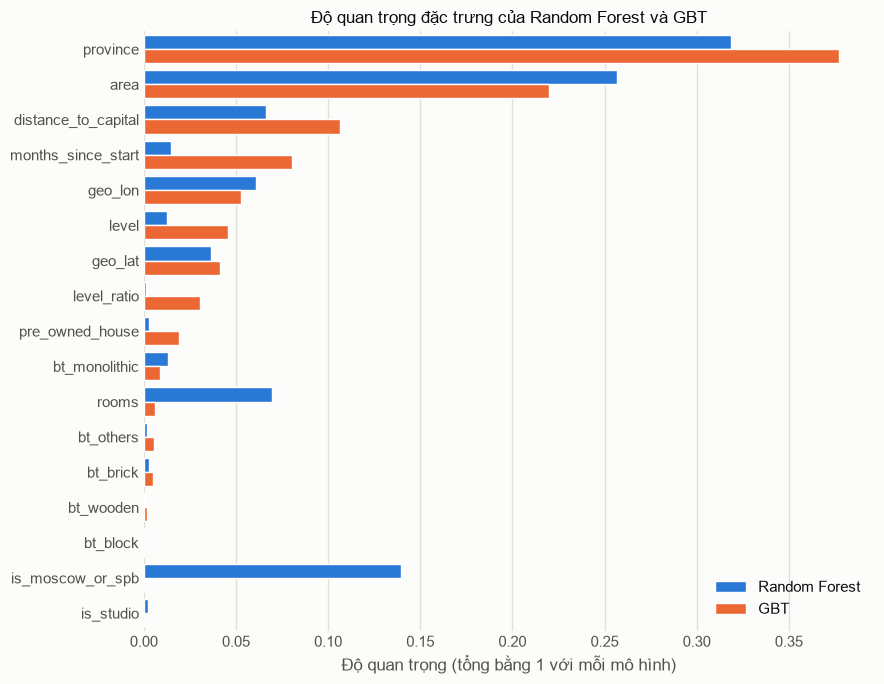

In [6]:
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="white", rc={
    "figure.facecolor": "#fcfcfb", "axes.facecolor": "#fcfcfb",
    "axes.edgecolor": "#c3c2b7", "grid.color": "#e1e0d9",
    "text.color": "#0b0b0b", "axes.labelcolor": "#52514e",
    "xtick.color": "#52514e", "ytick.color": "#52514e",
})
importance = (pd.DataFrame({name: fitted[name].featureImportances.toArray() for name in ["Random Forest", "GBT"]},
                           index=[f.removesuffix("_idx") for f in FEATURES])
                .sort_values("GBT", ascending=False))
imp_long = importance.rename_axis("feature").reset_index().melt(id_vars="feature", var_name="model", value_name="importance")

fig, ax = plt.subplots(figsize=(9, 7))
sns.barplot(data=imp_long, x="importance", y="feature", hue="model", hue_order=["Random Forest", "GBT"],
            palette={"Random Forest": "#2a78d6", "GBT": "#eb6834"}, saturation=1, ax=ax)
ax.set(xlabel="Độ quan trọng (tổng bằng 1 với mỗi mô hình)", ylabel=None, title="Độ quan trọng đặc trưng của Random Forest và GBT")
ax.legend(title=None, frameon=False, loc="lower right")
ax.grid(axis="x", linewidth=1)
ax.set_axisbelow(True)
ax.tick_params(length=0)
sns.despine(left=True, bottom=True)
plt.tight_layout()
plt.show()

## 6. GBT chung

Một GBT cho toàn bộ dữ liệu với bộ đặc trưng rút gọn: 7 đặc trưng, `months_since_start` và `province` (bỏ `is_studio`, `is_moscow_or_spb`, `building_type` và `rooms`), làm mốc so sánh cho hybrid ở mục 7. Mục này đọc lại `train_model.parquet` và `test_model.parquet`, chạy độc lập với các mục 2–5 (chỉ cần cell khởi tạo Spark).

In [7]:
from functools import reduce
from pyspark.ml import Pipeline
from pyspark.ml.feature import StringIndexer
from pyspark.sql import DataFrame

spark.catalog.clearCache()  # giải phóng dữ liệu đã cache ở các mục trên (nếu có)
FEATS = ["geo_lat", "geo_lon", "distance_to_capital", "area", "level", "level_ratio", "pre_owned_house", "months_since_start"]
big_city = F.col("province").isin("Moscow", "Saint Petersburg")

def load(path):
    return (spark.read.parquet(path).select("price", *FEATS, "province")
                 .withColumn("price", F.col("price").cast("double")).withColumn("label", F.log("price"))
                 .withColumn("group", F.when(big_city, "Moscow + Saint Petersburg").otherwise("Còn lại"))
                 .withColumn("segment", F.when(big_city, F.col("province")).otherwise("Còn lại")))

train_gbt = load("../data/train_model.parquet").cache()
test_gbt = load("../data/test_model.parquet").cache()
print(f"Train: {train_gbt.count():,} bản ghi | Test (05–06/2021): {test_gbt.count():,} bản ghi")

Train: 5,459,594 bản ghi | Test (05–06/2021): 1,572,995 bản ghi


Hàm tạo pipeline GBT (`province` qua StringIndexer, `maxBins=128` vì có 84 tỉnh, `maxIter=30`) và hàm tính metric trên giá rúp: R², MAE, RMSE, MAPE, MdAPE (sai số phần trăm trung vị) và độ lệch trung vị (dự đoán/thực − 1).

In [8]:
METRIC_FMT = {"R2": "{:.4f}", "MAE": "{:,.0f}", "RMSE": "{:,.0f}", "MAPE (%)": "{:.2f}", "MdAPE (%)": "{:.2f}",
              "Lệch trung vị (%)": "{:+.2f}"}

def gbt_pipeline(max_depth=6, step_size=0.1):
    return Pipeline(stages=[
        StringIndexer(inputCol="province", outputCol="province_idx", handleInvalid="keep"),
        VectorAssembler(inputCols=FEATS + ["province_idx"], outputCol="features"),
        GBTRegressor(featuresCol="features", labelCol="label", maxIter=30, maxDepth=max_depth, stepSize=step_size,
                     maxBins=128, seed=42)])

def to_rubles(model, df):
    return model.transform(df).select("price", "segment", F.exp("prediction").alias("pred_price"))

def evaluate_with_median(pred):
    err = F.col("price") - F.col("pred_price")
    mean_price = pred.agg(F.avg("price")).first()[0]
    return pred.agg((1 - F.sum(err ** 2) / F.sum((F.col("price") - F.lit(mean_price)) ** 2)).alias("R2"),
                    F.avg(F.abs(err)).alias("MAE"),
                    F.sqrt(F.avg(err ** 2)).alias("RMSE"),
                    (100 * F.avg(F.abs(err) / F.col("price"))).alias("MAPE (%)"),
                    (100 * F.percentile_approx(F.abs(err) / F.col("price"), 0.5, 10000)).alias("MdAPE (%)"),
                    (100 * (F.percentile_approx(F.col("pred_price") / F.col("price"), 0.5, 10000) - 1)).alias("Lệch trung vị (%)"),
                    ).first().asDict()

def metrics_table(preds):
    return (pd.DataFrame([{"Mô hình": name, **evaluate_with_median(p)} for name, p in preds.items()])
              .set_index("Mô hình").style.format(METRIC_FMT))

Huấn luyện GBT chung trên toàn bộ tập train (`maxDepth=6`, `stepSize=0.1`) và dự đoán trên tập test.

In [9]:
t0 = time.time()
gbt_all = gbt_pipeline().fit(train_gbt)
print(f"GBT chung: xong sau {time.time() - t0:.0f}s")
predictions = {"GBT chung": to_rubles(gbt_all, test_gbt).cache()}

GBT chung: xong sau 278s


## 7. Hybrid 2 nhóm

Chia dữ liệu thành 2 nhóm Moscow + Saint Petersburg và các vùng còn lại; mỗi nhóm một GBT với cùng đặc trưng và tham số như GBT chung, dự đoán của hai nhóm được ghép lại trên tập test.

In [10]:
GROUPS = ["Moscow + Saint Petersburg", "Còn lại"]

def fit_hybrid(params):
    """params: {nhóm: (maxDepth, stepSize)}; trả về dự đoán trên tập test của cả hai nhóm."""
    parts = []
    for g in GROUPS:
        t0 = time.time()
        model = gbt_pipeline(*params[g]).fit(train_gbt.filter(F.col("group") == g))
        print(f"{g}: maxDepth={params[g][0]}, stepSize={params[g][1]}, xong sau {time.time() - t0:.0f}s")
        parts.append(to_rubles(model, test_gbt.filter(F.col("group") == g)))
    return reduce(DataFrame.unionByName, parts).cache()

train_gbt.groupBy("group").count().show()
predictions["Hybrid 2 nhóm"] = fit_hybrid({g: (6, 0.1) for g in GROUPS})

+--------------------+-------+
|               group|  count|
+--------------------+-------+
|Moscow + Saint Pe...| 898056|
|             Còn lại|4561538|
+--------------------+-------+

Moscow + Saint Petersburg: maxDepth=6, stepSize=0.1, xong sau 73s
Còn lại: maxDepth=6, stepSize=0.1, xong sau 272s


So sánh GBT chung với hybrid 2 nhóm trên tập test.

In [11]:
metrics_table(predictions)

,R2,MAE,RMSE,MAPE (%),MdAPE (%),Lệch trung vị (%)
Mô hình,,,,,,
GBT chung,0.7880,"1,280,573","3,980,255",20.98,15.64,-5.70
Hybrid 2 nhóm,0.8200,"1,197,580","3,666,892",20.26,14.89,-5.41


MdAPE và độ lệch trung vị riêng cho Moscow, Saint Petersburg và các vùng còn lại.

In [12]:
SEGMENTS = ["Moscow", "Saint Petersburg", "Còn lại"]

def segment_table(preds):
    rel = F.col("pred_price") / F.col("price")
    rows = [pred.groupBy("segment")
                .agg((100 * F.percentile_approx(F.abs(rel - 1), 0.5, 10000)).alias("MdAPE (%)"),
                     (100 * (F.percentile_approx(rel, 0.5, 10000) - 1)).alias("Lệch trung vị (%)"))
                .toPandas().assign(**{"Mô hình": name})
            for name, pred in preds.items()]
    return (pd.concat(rows)
              .pivot_table(index="Mô hình", columns="segment", values=["MdAPE (%)", "Lệch trung vị (%)"], sort=False)
              .reindex(columns=SEGMENTS, level=1)
              .style.format("{:.2f}").format("{:+.2f}", subset=["Lệch trung vị (%)"]))

segment_table(predictions)

## 8. Tuning bằng grid search

Tìm `maxDepth` và `stepSize` tốt nhất cho từng nhóm, giữ `maxIter=30` và các tham số còn lại. Tập test không dùng để chọn tham số: lấy ngẫu nhiên 50% tập train, học trên các tháng đến 02/2021 và đánh giá trên 03–04/2021, giống cách tập test đứng sau tập train; tiêu chí chọn là RMSE của log(`price`) trên tập validation.

In [13]:
from pyspark.ml.evaluation import RegressionEvaluator

GRID = {"maxDepth": [5, 8, 12], "stepSize": [0.05, 0.1, 0.2]}
VAL_MONTHS = (37, 38)  # 03–04/2021; tháng 39 chỉ có ngày 01/05 nên không dùng
tune = train_gbt.sample(fraction=0.5, seed=42)
tune_train = tune.filter(F.col("months_since_start") < VAL_MONTHS[0]).cache()
tune_val = tune.filter(F.col("months_since_start").between(*VAL_MONTHS)).cache()
print(f"Tuning: học {tune_train.count():,} bản ghi | validation {tune_val.count():,} bản ghi")

Tuning: học 2,536,137 bản ghi | validation 188,721 bản ghi


Chạy lưới 3 × 3 tổ hợp cho mỗi nhóm, ghi RMSE trên tập validation và thời gian huấn luyện.

In [14]:
rmse = RegressionEvaluator(labelCol="label", predictionCol="prediction", metricName="rmse")
grid_rows = []
for g in GROUPS:
    tr, va = tune_train.filter(F.col("group") == g), tune_val.filter(F.col("group") == g)
    for depth in GRID["maxDepth"]:
        for step in GRID["stepSize"]:
            t0 = time.time()
            score = rmse.evaluate(gbt_pipeline(depth, step).fit(tr).transform(va))
            grid_rows.append({"Nhóm": g, "maxDepth": depth, "stepSize": step, "RMSE log(price)": score,
                              "Thời gian (s)": time.time() - t0})
            print(f"{g}: maxDepth={depth}, stepSize={step}, RMSE {score:.4f}, {time.time() - t0:.0f}s")
grid_results = pd.DataFrame(grid_rows)

Moscow + Saint Petersburg: maxDepth=5, stepSize=0.05, RMSE 0.2820, 40s
Moscow + Saint Petersburg: maxDepth=5, stepSize=0.1, RMSE 0.2569, 38s
Moscow + Saint Petersburg: maxDepth=5, stepSize=0.2, RMSE 0.2409, 38s
Moscow + Saint Petersburg: maxDepth=8, stepSize=0.05, RMSE 0.2432, 68s
Moscow + Saint Petersburg: maxDepth=8, stepSize=0.1, RMSE 0.2279, 67s
Moscow + Saint Petersburg: maxDepth=8, stepSize=0.2, RMSE 0.2205, 64s
Moscow + Saint Petersburg: maxDepth=12, stepSize=0.05, RMSE 0.2321, 318s
Moscow + Saint Petersburg: maxDepth=12, stepSize=0.1, RMSE 0.2304, 294s
Moscow + Saint Petersburg: maxDepth=12, stepSize=0.2, RMSE 0.2331, 281s
Còn lại: maxDepth=5, stepSize=0.05, RMSE 0.3079, 94s
Còn lại: maxDepth=5, stepSize=0.1, RMSE 0.2728, 90s
Còn lại: maxDepth=5, stepSize=0.2, RMSE 0.2522, 88s
Còn lại: maxDepth=8, stepSize=0.05, RMSE 0.2616, 150s
Còn lại: maxDepth=8, stepSize=0.1, RMSE 0.2422, 151s
Còn lại: maxDepth=8, stepSize=0.2, RMSE 0.2279, 167s
Còn lại: maxDepth=12, stepSize=0.05, RMSE 0.

RMSE theo lưới tham số của từng nhóm (hàng: `maxDepth`, cột: `stepSize`) và bộ tham số tốt nhất.

In [15]:
best = grid_results.loc[grid_results.groupby("Nhóm")["RMSE log(price)"].idxmin()].set_index("Nhóm")
best_params = {g: (int(best.loc[g, "maxDepth"]), float(best.loc[g, "stepSize"])) for g in GROUPS}
print("Tham số tốt nhất:", best_params)
grid_results.pivot_table(index=["Nhóm", "maxDepth"], columns="stepSize", values="RMSE log(price)", sort=False).style.format("{:.4f}")

Tham số tốt nhất: {'Moscow + Saint Petersburg': (8, 0.2), 'Còn lại': (12, 0.2)}


Huấn luyện lại hybrid 2 nhóm trên toàn bộ tập train với tham số tốt nhất của từng nhóm, rồi so sánh ba mô hình trên tập test.

In [16]:
predictions["Hybrid 2 nhóm (đã tuning)"] = fit_hybrid(best_params)
metrics_table(predictions)

Moscow + Saint Petersburg: maxDepth=8, stepSize=0.2, xong sau 89s
Còn lại: maxDepth=12, stepSize=0.2, xong sau 795s


,R2,MAE,RMSE,MAPE (%),MdAPE (%),Lệch trung vị (%)
Mô hình,,,,,,
GBT chung,0.7880,"1,280,573","3,980,255",20.98,15.64,-5.70
Hybrid 2 nhóm,0.8200,"1,197,580","3,666,892",20.26,14.89,-5.41
Hybrid 2 nhóm (đã tuning),0.7870,"1,111,066","3,989,312",18.57,12.73,-1.97


MdAPE và độ lệch trung vị theo nhóm vùng của ba mô hình.

In [17]:
segment_table(predictions)

## 9. Trực quan hóa kết quả dự đoán

Lấy mẫu ngẫu nhiên 10% dự đoán trên tập test của hybrid 2 nhóm đã tuning (khoảng 157 nghìn bản ghi) để vẽ, dùng cùng bảng màu ba nhóm vùng như notebook 02.

In [ ]:
import numpy as np
from matplotlib.colors import LogNorm
from matplotlib.ticker import FuncFormatter, PercentFormatter

compact = FuncFormatter(lambda x, _: next((f"{x / d:g}{s}" for d, s in ((1e9, "B"), (1e6, "M"), (1e3, "K")) if abs(x) >= d), f"{x:g}"))
SEG_COLORS = {"Moscow": "#e34948", "Saint Petersburg": "#2a78d6", "Còn lại": "#008300"}
MODEL_COLORS = dict(zip(predictions, ["#2a78d6", "#eb6834", "#1baf7a"]))
BEST = "Hybrid 2 nhóm (đã tuning)"

viz = predictions[BEST].sample(fraction=0.1, seed=42).toPandas()
viz["segment"] = pd.Categorical(viz["segment"], categories=SEGMENTS)
viz["error_pct"] = 100 * (viz["pred_price"] / viz["price"] - 1)
print(f"Mẫu trực quan hóa: {len(viz):,} bản ghi")

Mẫu trực quan hóa: 157,334 bản ghi


Giá thực và giá dự đoán theo nhóm vùng trên thang log: ô càng đậm càng nhiều bản ghi, đường chéo là dự đoán đúng giá thực.

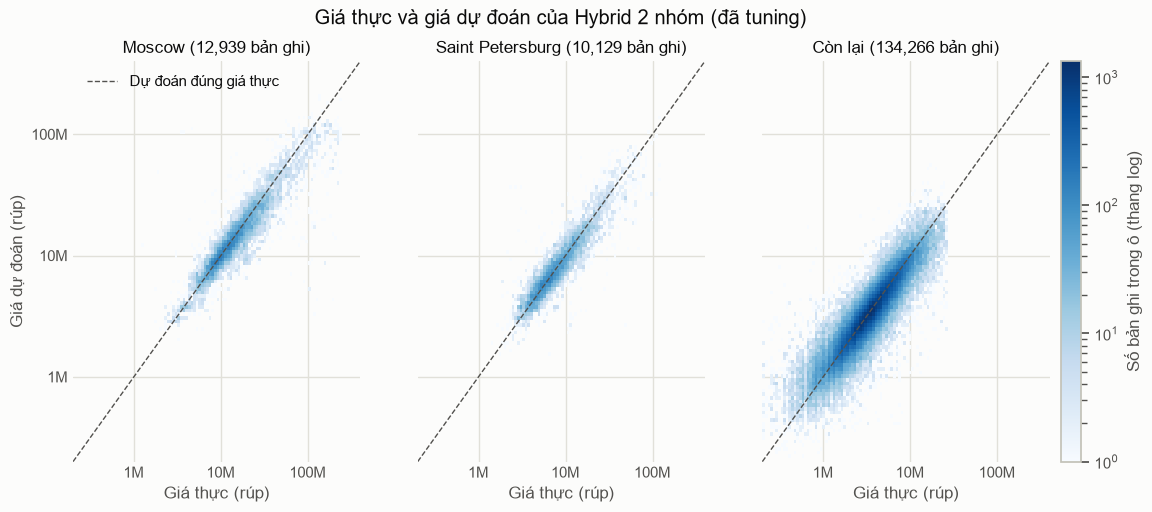

In [ ]:
lims, ticks = (2e5, 4e8), [1e6, 1e7, 1e8]
fig, axes = plt.subplots(1, 3, figsize=(15, 5.2), sharex=True, sharey=True)
for ax, seg in zip(axes, SEGMENTS):
    part = viz[viz["segment"] == seg]
    sns.histplot(data=part, x="price", y="pred_price", log_scale=True, bins=110, binrange=(np.log10(lims), np.log10(lims)),
                 cmap="Blues", ax=ax)
    ax.plot(lims, lims, color="#52514e", linestyle="--", linewidth=1, label="Dự đoán đúng giá thực")
    ax.set(xlim=lims, ylim=lims, xticks=ticks, yticks=ticks, xlabel="Giá thực (rúp)", ylabel="Giá dự đoán (rúp)",
           title=f"{seg} ({len(part):,} bản ghi)")
    ax.minorticks_off()
    ax.xaxis.set_major_formatter(compact)
    ax.yaxis.set_major_formatter(compact)
    ax.grid(linewidth=1)
    ax.set_axisbelow(True)
    ax.tick_params(length=0)
# cùng một thang màu log cho cả ba panel để so sánh được mật độ
meshes = [ax.collections[0] for ax in axes]
norm = LogNorm(vmin=1, vmax=max(m.get_array().max() for m in meshes))
for m in meshes:
    m.set_norm(norm)
axes[0].legend(frameon=False, loc="upper left")
fig.colorbar(meshes[0], ax=axes, label="Số bản ghi trong ô (thang log)", pad=0.01)
sns.despine(left=True, bottom=True)
fig.suptitle(f"Giá thực và giá dự đoán của {BEST}", x=0.45)
plt.show()

Phân phối sai số tương đối (dự đoán/thực − 1) theo nhóm vùng, giá trị âm là đoán thấp hơn giá thực.

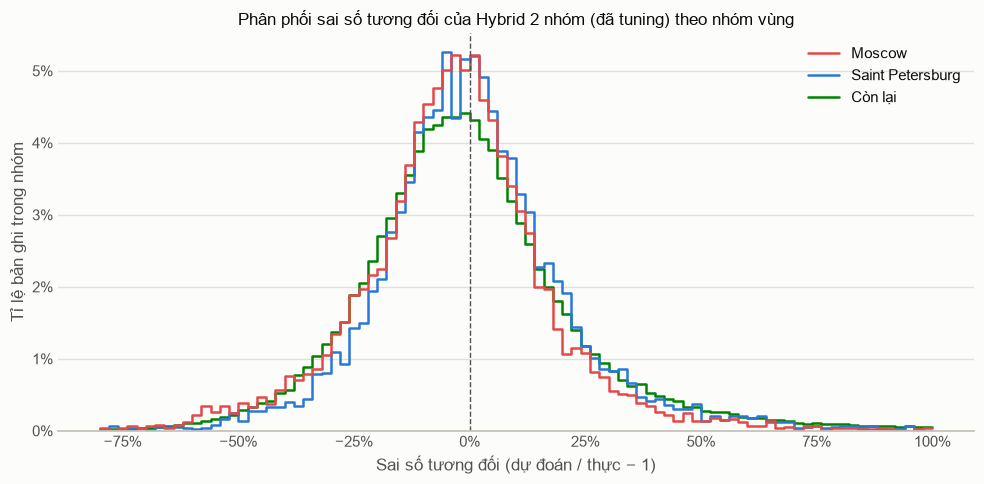

In [ ]:
fig, ax = plt.subplots(figsize=(10, 5))
sns.histplot(data=viz, x="error_pct", hue="segment", hue_order=SEGMENTS, palette=SEG_COLORS, binrange=(-80, 100), binwidth=2,
             stat="percent", common_norm=False, element="step", fill=False, linewidth=1.8, ax=ax)
ax.axvline(0, color="#52514e", linestyle="--", linewidth=1)
ax.xaxis.set_major_formatter(PercentFormatter(decimals=0))
ax.yaxis.set_major_formatter(PercentFormatter(decimals=0))
ax.set(xlabel="Sai số tương đối (dự đoán / thực − 1)", ylabel="Tỉ lệ bản ghi trong nhóm",
       title=f"Phân phối sai số tương đối của {BEST} theo nhóm vùng")
sns.move_legend(ax, "upper right", title=None, frameon=False)
ax.grid(axis="y", linewidth=1)
ax.set_axisbelow(True)
ax.tick_params(length=0)
sns.despine(left=True)
plt.tight_layout()
plt.show()

Sai số tương đối theo mức giá thực, mỗi nhóm vùng được chia thành 10 nhóm giá có số bản ghi bằng nhau.

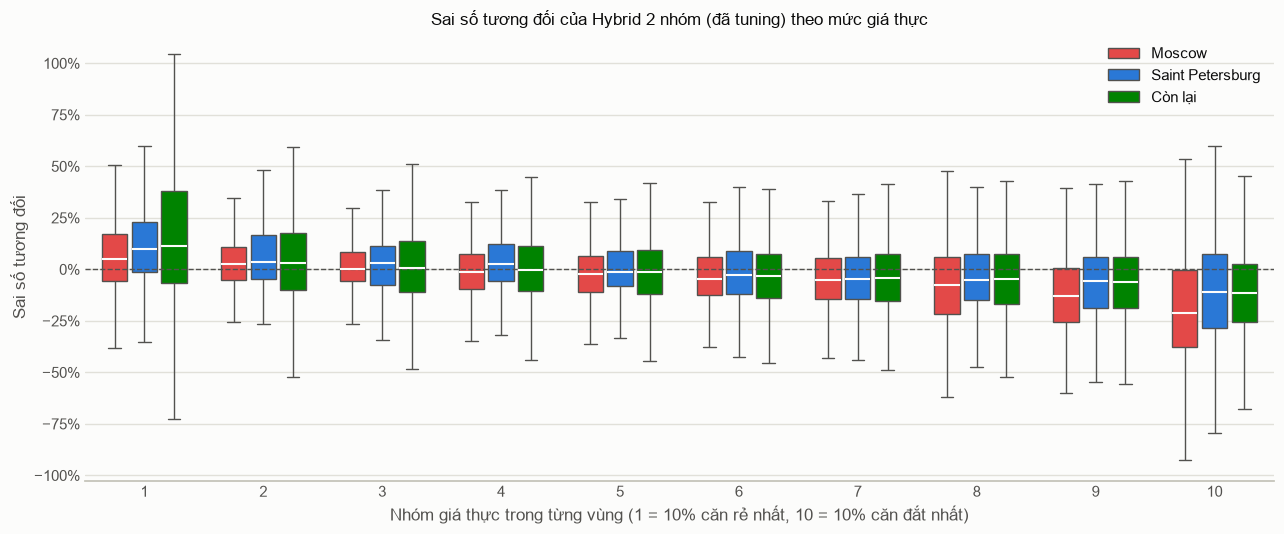

In [ ]:
viz["price_decile"] = viz.groupby("segment", observed=True)["price"].transform(lambda s: pd.qcut(s, 10, labels=False, duplicates="drop") + 1)
fig, ax = plt.subplots(figsize=(13, 5.5))
sns.boxplot(data=viz, x="price_decile", y="error_pct", hue="segment", hue_order=SEGMENTS, palette=SEG_COLORS, showfliers=False,
            width=0.75, saturation=1, gap=0.15, linecolor="#52514e", linewidth=1, medianprops={"color": "#fcfcfb", "linewidth": 1.5}, ax=ax)
ax.axhline(0, color="#52514e", linestyle="--", linewidth=1)
ax.yaxis.set_major_formatter(PercentFormatter(decimals=0))
ax.set(xlabel="Nhóm giá thực trong từng vùng (1 = 10% căn rẻ nhất, 10 = 10% căn đắt nhất)", ylabel="Sai số tương đối",
       title=f"Sai số tương đối của {BEST} theo mức giá thực")
sns.move_legend(ax, "upper right", title=None, frameon=False)
ax.grid(axis="y", linewidth=1)
ax.set_axisbelow(True)
ax.tick_params(length=0)
sns.despine(left=True)
plt.tight_layout()
plt.show()

Tỉ lệ bản ghi có sai số phần trăm tuyệt đối không vượt quá từng mức của ba mô hình, đường càng cao càng tốt.

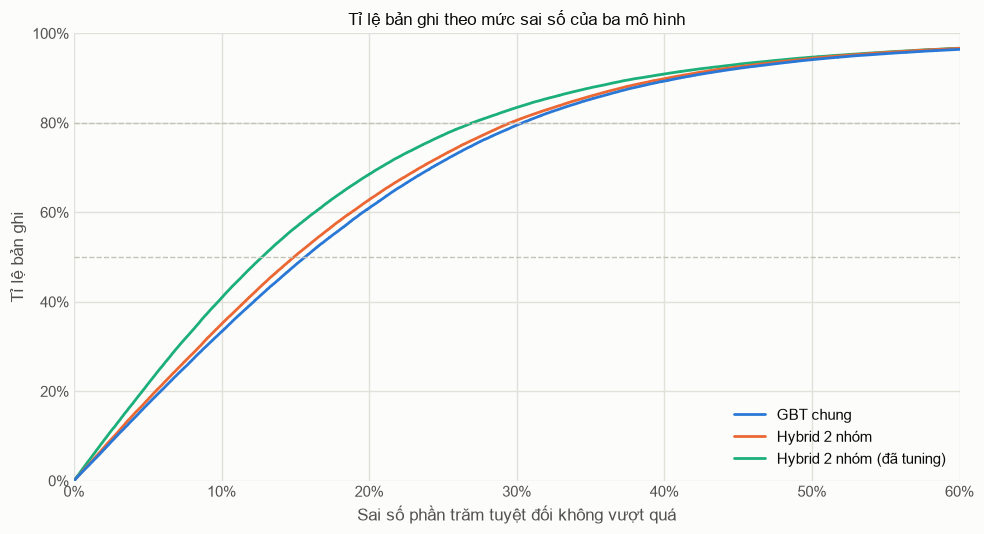

In [ ]:
ape = pd.concat([pred.sample(fraction=0.1, seed=42)
                     .select((100 * F.abs(F.col("pred_price") / F.col("price") - 1)).alias("ape")).toPandas().assign(model=name)
                 for name, pred in predictions.items()], ignore_index=True)
fig, ax = plt.subplots(figsize=(10, 5.5))
sns.ecdfplot(data=ape, x="ape", hue="model", hue_order=list(predictions), palette=MODEL_COLORS, stat="percent", linewidth=2, ax=ax)
for level in (50, 80):
    ax.axhline(level, color="#c3c2b7", linestyle="--", linewidth=1)
ax.set_xlim(0, 60)
ax.set_ylim(0, 100)
ax.xaxis.set_major_formatter(PercentFormatter(decimals=0))
ax.yaxis.set_major_formatter(PercentFormatter(decimals=0))
ax.set(xlabel="Sai số phần trăm tuyệt đối không vượt quá", ylabel="Tỉ lệ bản ghi",
       title="Tỉ lệ bản ghi theo mức sai số của ba mô hình")
sns.move_legend(ax, "lower right", title=None, frameon=False)
ax.grid(linewidth=1)
ax.set_axisbelow(True)
ax.tick_params(length=0)
sns.despine(left=True, bottom=True)
plt.tight_layout()
plt.show()